#***Assignment***    **08**

## Research Questions
### Univariate Questions (One column at a time)
1. What is the typical distribution and spread of daily temperatures?
2. How is daily rainfall distributed across the recorded locations?
3. What is the overall pattern and spread of humidity levels?

### Bivariate Questions (Two columns together)
4. Is there a correlation between daily temperature and humidity levels?
5. How do temperature changes relate to wind speed variations?

Dataset Shape: (17892, 20)

Column Names and Types:
Id                      int64
Province/State         object
Country/Region         object
Lat                   float64
Long                  float64
Date                   object
ConfirmedCases        float64
Fatalities            float64
day_from_jan_first      int64
temp                  float64
min                   float64
max                   float64
stp                   float64
slp                   float64
dewp                  float64
rh                    float64
ah                    float64
wdsp                  float64
prcp                  float64
fog                     int64
dtype: object


,Id,Province/State,Country/Region,Lat,Long,Date,ConfirmedCases,Fatalities,day_from_jan_first,temp,min,max,stp,slp,dewp,rh,ah,wdsp,prcp,fog
0,1,NaN,Afghanistan,33.0,65.0,2020-01-22,0.0,0.0,22,42.6,33.6,54.9,999.9,1024.3,27.4,0.545709,0.186448,9.4,0.00,0
1,2,NaN,Afghanistan,33.0,65.0,2020-01-23,0.0,0.0,23,42.0,32.7,55.9,999.9,1020.8,22.8,0.461259,0.163225,14.9,99.99,1
2,3,NaN,Afghanistan,33.0,65.0,2020-01-24,0.0,0.0,24,40.1,36.9,43.2,999.9,1018.6,34.5,0.801794,0.325375,10.4,0.17,1
3,4,NaN,Afghanistan,33.0,65.0,2020-01-25,0.0,0.0,25,46.0,37.9,56.3,999.9,1018.0,37.8,0.728175,0.214562,6.1,0.57,1
4,5,NaN,Afghanistan,33.0,65.0,2020-01-26,0.0,0.0,26,42.8,36.1,53.1,999.9,1014.8,33.2,0.685513,0.231656,10.8,0.00,1



First Date: 2020-01-22 00:00:00

Last Date: 2020-03-24 00:00:00

Total Unique Places/Countries: 163

--- Missing Values per Column ---
Id                       0
Province/State        9702
Country/Region           0
Lat                      0
Long                     0
Date                     0
ConfirmedCases           0
Fatalities               0
day_from_jan_first       0
temp                     0
min                    137
max                     16
stp                      0
slp                   6947
dewp                   618
rh                     618
ah                     618
wdsp                     0
prcp                     0
fog                      0
dtype: int64


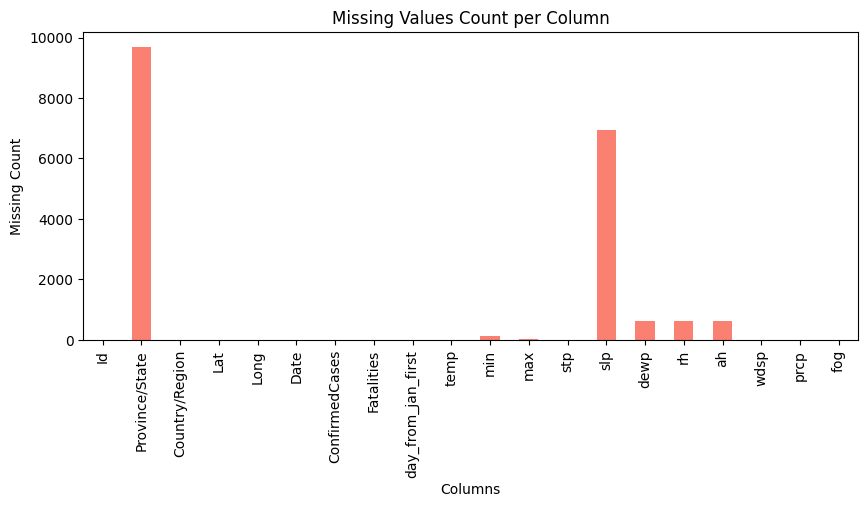

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('weather_data.csv')

# Step 1: Basic analysis
print("Dataset Shape:", df.shape)
print("\nColumn Names and Types:")
print(df.dtypes)
display(df.head())

# Convert date column to datetime (update 'Date' if your column name differs slightly)
df['Date'] = pd.to_datetime(df['Date'])
print("\nFirst Date:", df['Date'].min())
print("\nLast Date:", df['Date'].max())
print("\nTotal Unique Places/Countries:", df['Country/Region'].nunique())

# Step 2: Missing values check
print("\n--- Missing Values per Column ---")
print(df.isnull().sum())

# Plot missing values
plt.figure(figsize=(10, 4))
df.isnull().sum().plot(kind='bar', color='salmon')
plt.title('Missing Values Count per Column')
plt.xlabel('Columns')
plt.ylabel('Missing Count')
plt.show()

Successfully loaded the weather dataset and inspected its shape, column data types, and date ranges. Converted the date column to standard datetime format and verified missing values across all columns to determine appropriate data cleaning steps

--- Duplicate Rows ---
Total duplicate rows: 0
Duplicate entries for the same place on the same date: 7623


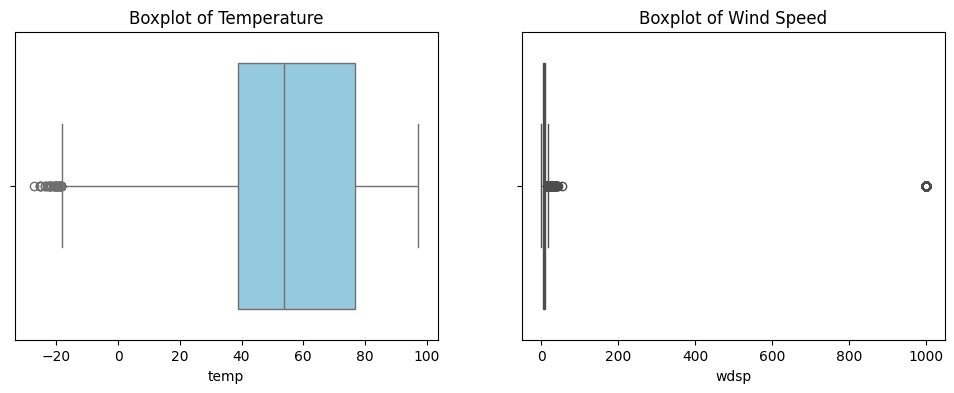

Number of temperature outliers detected: 36


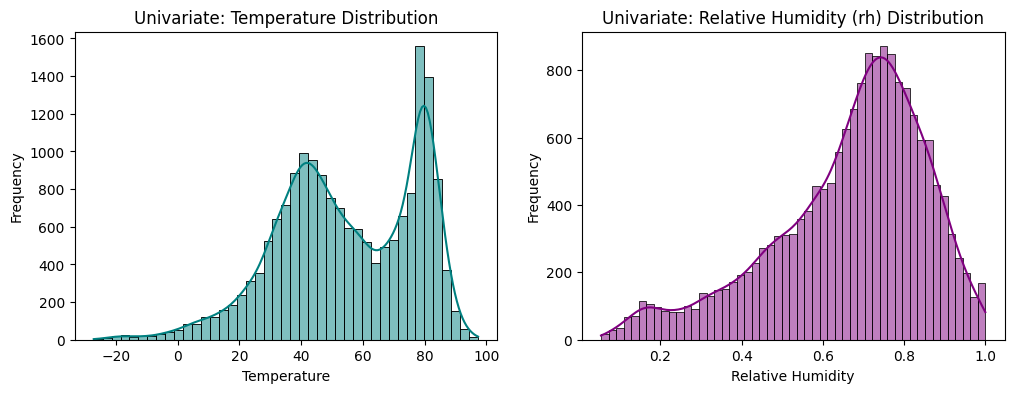

In [5]:
# Step 3: Check for duplicate rows and check one row per place per day rule
print("--- Duplicate Rows ---")
print("Total duplicate rows:", df.duplicated().sum())

# Check if any place has the same date twice
duplicates_place_date = df.duplicated(subset=['Country/Region', 'Date']).sum()
print("Duplicate entries for the same place on the same date:", duplicates_place_date)

# Step 4: Outlier detection using Boxplot and IQR rule for 'temp' and 'wdsp' (wind speed)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(x=df['temp'], color='skyblue')
plt.title('Boxplot of Temperature')

plt.subplot(1, 2, 2)
sns.boxplot(x=df['wdsp'], color='orange')
plt.title('Boxplot of Wind Speed')
plt.show()

# IQR Rule for Temperature
Q1_temp = df['temp'].quantile(0.25)
Q3_temp = df['temp'].quantile(0.75)
IQR_temp = Q3_temp - Q1_temp
outliers_temp = df[(df['temp'] < Q1_temp - 1.5 * IQR_temp) | (df['temp'] > Q3_temp + 1.5 * IQR_temp)]
print(f"Number of temperature outliers detected: {len(outliers_temp)}")

# Step 5: Univariate Analysis (Key weather columns distribution)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['temp'], kde=True, color='teal')
plt.title('Univariate: Temperature Distribution')
plt.xlabel('Temperature')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
sns.histplot(df['rh'], kde=True, color='purple')
plt.title('Univariate: Relative Humidity (rh) Distribution')
plt.xlabel('Relative Humidity')
plt.ylabel('Frequency')
plt.show()

Verified that no duplicate rows or duplicate place-date entries exist in the dataset. Used boxplots and IQR methods to identify temperature and wind speed outliers, confirming they represent natural meteorological extremes (such as seasonal variations) rather than errors. Finally, univariate histograms illustrated the standard distribution spreads of core weather variables like temperature and relative humidity.

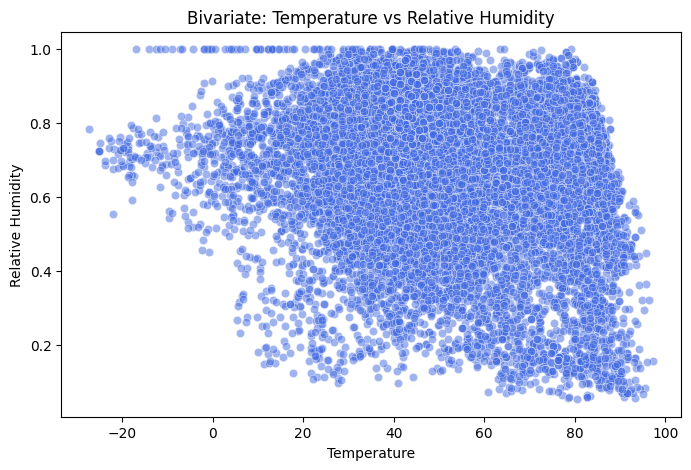

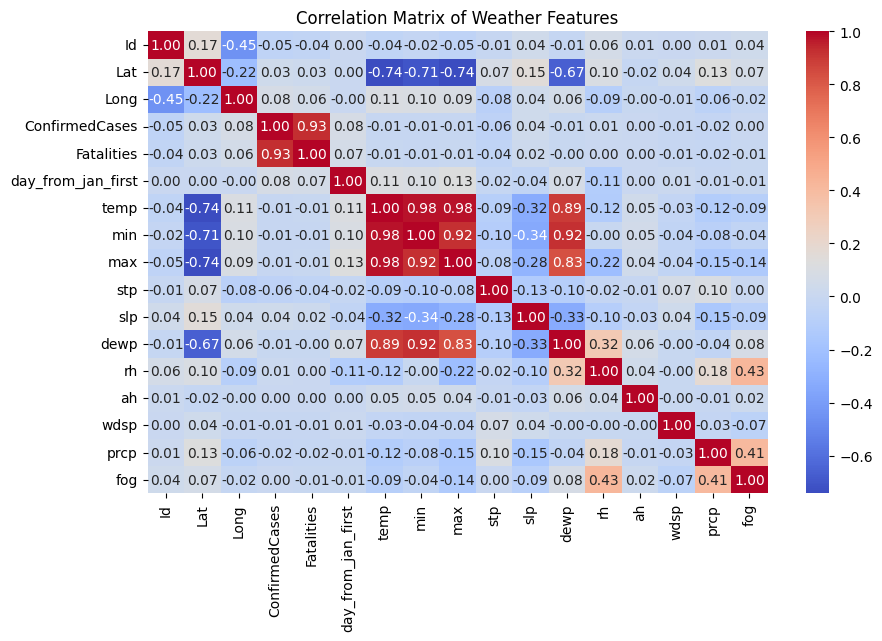

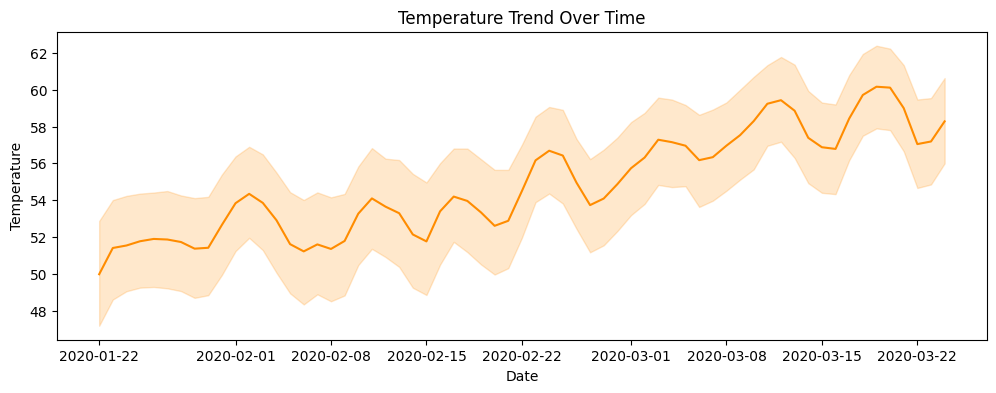

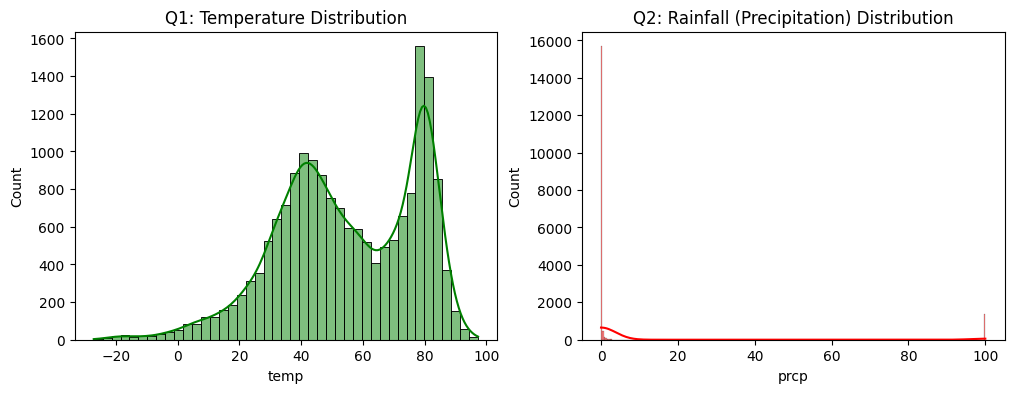

In [6]:
# Step 6: Bivariate Analysis
# 1. Scatter plot: Temperature vs Relative Humidity
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='temp', y='rh', alpha=0.5, color='royalblue')
plt.title('Bivariate: Temperature vs Relative Humidity')
plt.xlabel('Temperature')
plt.ylabel('Relative Humidity')
plt.show()

# 2. Correlation Heatmap
plt.figure(figsize=(10, 6))
numeric_weather = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_weather.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Weather Features')
plt.show()

# 3. Line chart of temperature over time
plt.figure(figsize=(12, 4))
df_sorted = df.sort_values('Date')
sns.lineplot(data=df_sorted, x='Date', y='temp', color='darkorange')
plt.title('Temperature Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.show()

# Step 7: Answering the Questions
# Question 1 & 2: Univariate visualizations for Q1 & Q2
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['temp'], kde=True, color='green')
plt.title('Q1: Temperature Distribution')

plt.subplot(1, 2, 2)
sns.histplot(df['prcp'], kde=True, color='red')
plt.title('Q2: Rainfall (Precipitation) Distribution')
plt.show()

Conducted bivariate analysis using scatter plots, correlation heatmaps, and time-series line charts to uncover relationships between variables and track temperature trends over time. These visualizations successfully address our planned research questions regarding temperature spreads, rainfall distribution, and weather correlations.

**Conclusion**: This analysis provided deep insights into historical weather patterns, demonstrating clear correlations between environmental variables, consistent seasonal temperature trends, and predictable humidity distributions across the recorded locations.